# Data Slayer 4.0 Baseline CV Notebook

Objective: Mengklasifikasikan klip ujian berdurasi 1 detik (30 frame) menjadi normal (0) atau cheating (1) dengan fitur per frame dari DINOv3 ViT-H+ dan model temporal kecil di atasnya, menggunakan F1-Macro sebagai metrik evaluasi.

# Sinkronisasi versi modules dan libraries

In [1]:
import sys
print(sys.version)
%pip install -q torch==2.11.0 timm==1.0.29 opencv-python==5.0.0.93 scikit-learn==1.8.0 numpy==2.4.4 pandas==2.3.3 matplotlib==3.10.9 tqdm==4.67.3

3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\leouw\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


# Import modules dan libraries

In [2]:
import random
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import timm
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from tqdm.auto import tqdm

SEED = 42
DATA = Path("../data")
BACKBONE = "vit_huge_plus_patch16_dinov3.lvd1689m"
IMG_HW = (224, 400)
STEP = 3
WIN = 10
N_FOLDS = 5
CACHE = Path(f"../cache/dinov3_hplus_{IMG_HW[0]}x{IMG_HW[1]}_step{STEP}_bf16")
CHEAT_ACTIONS = ["Looking_Under_the_Desk", "Reading_Hidden_Notes", "Repeated_Peeking", "Using_Smartwatch"]
NORMAL_ACTIONS = ["Checking_Smartwatch", "Looking_Around", "Thinking", "Writing_Answers"]
ACTIONS = CHEAT_ACTIONS + NORMAL_ACTIONS
DEVICE = "cuda"


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything(SEED)
print(torch.__version__, torch.cuda.get_device_name(0))

2.11.0+cu128 NVIDIA GeForce RTX 4070 Laptop GPU


# Import datasets

In [3]:
rows = []
for path in sorted(DATA.glob("train/*/*/*.MOV")):
    view, action = path.stem.split("_", 1)
    rows.append({
        "video": f"{path.parent.parent.name}/{path.parent.name}/{path.stem}",
        "path": str(path),
        "label": int(path.parent.parent.name == "cheat"),
        "subject": int(path.parent.name.split("_")[1]),
        "view": view,
        "action": action,
    })
train = pd.DataFrame(rows)
train["action_id"] = train["action"].map(ACTIONS.index)
sub = pd.read_csv(DATA / "sample_submission.csv")
print(train.shape, sub.shape)
train.head()

(416, 7) (1515, 2)


,video,path,label,subject,view,action,action_id
0,cheat/subject_1/front_Looking_Under_the_Desk,..\data\train\cheat\subject_1\front_Looking_Un...,1,1,front,Looking_Under_the_Desk,0
1,cheat/subject_1/front_Reading_Hidden_Notes,..\data\train\cheat\subject_1\front_Reading_Hi...,1,1,front,Reading_Hidden_Notes,1
2,cheat/subject_1/front_Repeated_Peeking,..\data\train\cheat\subject_1\front_Repeated_P...,1,1,front,Repeated_Peeking,2
3,cheat/subject_1/front_Using_Smartwatch,..\data\train\cheat\subject_1\front_Using_Smar...,1,1,front,Using_Smartwatch,3
4,cheat/subject_1/side_Looking_Under_the_Desk,..\data\train\cheat\subject_1\side_Looking_Und...,1,1,side,Looking_Under_the_Desk,0


# EDA

### Jumlah video per aksi dan sudut kamera
Setiap subjek punya 8 aksi (4 cheat, 4 normal) dari 2 sudut kamera, jadi nama aksi bisa dipakai sebagai label yang lebih rinci daripada cheat/normal.

In [4]:
print("subjek:", train["subject"].nunique(), "| video:", len(train))
train.pivot_table(index=["label", "action"], columns="view", values="video", aggfunc="count")

subjek: 26 | video: 416


view                          front  side
label action                             
0     Checking_Smartwatch        26    26
      Looking_Around             26    26
      Thinking                   26    26
      Writing_Answers            26    26
1     Looking_Under_the_Desk     26    26
      Reading_Hidden_Notes       26    26
      Repeated_Peeking           26    26
      Using_Smartwatch           26    26

### Durasi video train dan bentuk klip test
Video train berdurasi belasan detik, sedangkan setiap klip test hanya berisi 30 frame.

In [5]:
def video_info(path):
    cap = cv2.VideoCapture(path)
    info = (int(cap.get(cv2.CAP_PROP_FRAME_COUNT)), cap.get(cv2.CAP_PROP_FPS), int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))
    cap.release()
    return info


train[["n_frames", "fps", "width", "height"]] = [video_info(p) for p in train["path"]]
test_counts = pd.Series({d.name: len(list(d.glob("*.jpg"))) for d in sorted(DATA.glob("test/*"))})
test_shape = cv2.imread(str(DATA / "test" / sub["id"][0] / "01.jpg")).shape
print("frame per klip test:", test_counts.unique(), "| ukuran frame test:", test_shape)
train[["n_frames", "fps", "width", "height"]].describe().loc[["min", "50%", "max"]]

frame per klip test: [30] | ukuran frame test: (360, 640, 3)


,n_frames,fps,width,height
min,407.0,29.972184,1280.0,720.0
50%,477.0,29.987740,1280.0,720.0
max,558.0,30.000000,1280.0,720.0


### Jarak antar frame pada klip test
Membandingkan rata-rata perubahan piksel antar frame klip test dengan video train pada beberapa jarak frame, untuk mengetahui klip test dipotong dengan jarak berapa.

In [6]:
def small_gray(img):
    img = cv2.resize(img, (160, 90), interpolation=cv2.INTER_AREA)
    return cv2.GaussianBlur(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), (5, 5), 0).astype(np.float32)


rng = np.random.default_rng(SEED)
test_diff = []
for seq in rng.choice(sub["id"], 100, replace=False):
    frames = [small_gray(cv2.imread(str(p))) for p in sorted((DATA / "test" / seq).glob("*.jpg"))]
    test_diff.append(np.mean([np.abs(b - a).mean() for a, b in zip(frames, frames[1:])]))
train_diff = {s: [] for s in (1, 2, 3, 5)}
for path in rng.choice(train["path"], 20, replace=False):
    cap = cv2.VideoCapture(path)
    frames = []
    while len(frames) < 150:
        ok, img = cap.read()
        if not ok:
            break
        frames.append(small_gray(img))
    cap.release()
    for s in train_diff:
        train_diff[s].append(np.mean([np.abs(frames[i + s] - frames[i]).mean() for i in range(0, len(frames) - s, s)]))
print(f"test, frame berurutan : {np.median(test_diff):.3f}")
for s, v in train_diff.items():
    print(f"train, jarak {s} frame  : {np.median(v):.3f}")

test, frame berurutan : 0.181
train, jarak 1 frame  : 0.136
train, jarak 2 frame  : 0.195
train, jarak 3 frame  : 0.232
train, jarak 5 frame  : 0.291


### Contoh frame train dan test

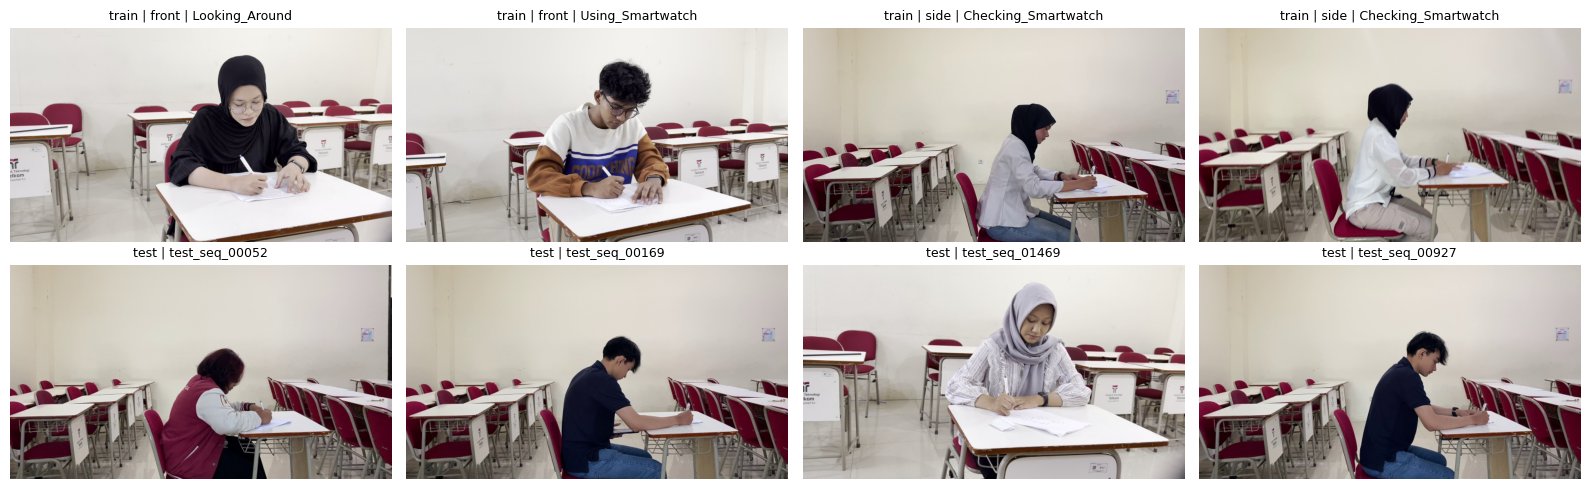

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(16, 5))
for ax, (_, row) in zip(axes[0], train.groupby("view").sample(2, random_state=SEED).iterrows()):
    cap = cv2.VideoCapture(row["path"])
    ok, img = cap.read()
    cap.release()
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(f"train | {row['view']} | {row['action']}", fontsize=9)
for ax, seq in zip(axes[1], sub["id"].sample(4, random_state=SEED)):
    ax.imshow(cv2.cvtColor(cv2.imread(str(DATA / "test" / seq / "01.jpg")), cv2.COLOR_BGR2RGB))
    ax.set_title(f"test | {seq}", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

# Feature Extraction

### DINOv3 ViT-H+
Backbone dibekukan dan dipakai sebagai encoder per frame dengan autocast bf16, karena aktivasi di dalam model melebihi batas fp16 dan menghasilkan NaN. Setiap frame menjadi vektor 2560 dimensi:
- cls: token CLS, ringkasan seluruh frame.
- patch_mean: rata-rata token patch, membawa detail lokal seperti posisi tangan dan kepala.

In [8]:
backbone = timm.create_model(BACKBONE, pretrained=True, num_classes=0, img_size=IMG_HW).to(DEVICE).eval()
MEAN = torch.tensor(backbone.pretrained_cfg["mean"], device=DEVICE).view(1, 3, 1, 1)
STD = torch.tensor(backbone.pretrained_cfg["std"], device=DEVICE).view(1, 3, 1, 1)


def to_input(img_bgr):
    img = cv2.resize(img_bgr, (IMG_HW[1], IMG_HW[0]), interpolation=cv2.INTER_AREA)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


@torch.inference_mode()
def embed(frames, batch_size=32):
    out = []
    for i in range(0, len(frames), batch_size):
        x = torch.from_numpy(np.stack(frames[i:i + batch_size])).to(DEVICE).permute(0, 3, 1, 2).float().div(255)
        with torch.autocast(DEVICE, dtype=torch.bfloat16):
            tokens = backbone.forward_features((x - MEAN) / STD)
        feat = torch.cat([tokens[:, 0], tokens[:, backbone.num_prefix_tokens:].mean(1)], dim=1).float()
        assert torch.isfinite(feat).all(), "fitur mengandung NaN/inf"
        out.append(feat.cpu().numpy().astype(np.float16))
    return np.concatenate(out)


print(BACKBONE, "| dimensi fitur per frame:", backbone.num_features * 2)

vit_huge_plus_patch16_dinov3.lvd1689m | dimensi fitur per frame: 2560


### Ekstraksi fitur train
Mengambil 1 dari setiap 3 frame video train (10 fps), karena frame yang bersebelahan hampir identik, lalu menyimpan fiturnya per video agar ekstraksi hanya dijalankan sekali.

In [9]:
(CACHE / "train").mkdir(parents=True, exist_ok=True)
for row in tqdm(train.itertuples(), total=len(train)):
    out_path = CACHE / "train" / (row.video.replace("/", "__") + ".npy")
    if out_path.exists():
        continue
    cap = cv2.VideoCapture(row.path)
    frames, i = [], 0
    while cap.grab():
        if i % STEP == 0:
            ok, img = cap.retrieve()
            if ok:
                frames.append(to_input(img))
        i += 1
    cap.release()
    np.save(out_path, embed(frames))
train_feats = [np.load(CACHE / "train" / (v.replace("/", "__") + ".npy")) for v in train["video"]]
train["n_sampled"] = [len(f) for f in train_feats]
print("total frame train terekstrak:", train["n_sampled"].sum(), "| bentuk satu video:", train_feats[0].shape)

  0%|          | 0/416 [00:00<?, ?it/s]

total frame train terekstrak: 66795 | bentuk satu video: (136, 2560)


### Ekstraksi fitur test
Klip test diambil dengan jarak frame yang sama (frame 01, 04, ..., 28), sehingga setiap klip menjadi 10 frame seperti window pada train.

In [10]:
test_path = CACHE / "test.npy"
if test_path.exists():
    X_test = np.load(test_path)
else:
    X_test = []
    for seq in tqdm(sub["id"]):
        files = sorted((DATA / "test" / seq).glob("*.jpg"))[::STEP]
        X_test.append(embed([to_input(cv2.imread(str(p))) for p in files]))
    X_test = np.stack(X_test)
    np.save(test_path, X_test)
del backbone
torch.cuda.empty_cache()
print("bentuk fitur test:", X_test.shape)

  0%|          | 0/1515 [00:00<?, ?it/s]

bentuk fitur test: (1515, 10, 2560)


# Preprocessing

### Pemotongan window
Memotong setiap video train menjadi window 10 frame (1 detik) yang tidak saling tumpang tindih, agar satu sampel train sama bentuknya dengan satu klip test. Label window mengikuti label videonya.

In [11]:
win_rows, win_feats = [], []
for vid, feats in enumerate(train_feats):
    for start in range(0, len(feats) - WIN + 1, WIN):
        win_rows.append({"vid": vid, "start": start})
        win_feats.append(feats[start:start + WIN])
windows = pd.DataFrame(win_rows).join(train[["label", "action_id", "action", "view", "subject"]], on="vid")
X_win = np.stack(win_feats)
print("bentuk window train:", X_win.shape)
windows.groupby("label").size()

bentuk window train: (6477, 10, 2560)


label
0    3210
1    3267
dtype: int64

### Pembagian fold per subjek
Semua video dari satu subjek berada di fold yang sama, sehingga skor validasi mengukur kemampuan model pada orang yang belum pernah dilihat.

In [12]:
train["fold"] = -1
splitter = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
for fold, (_, val_idx) in enumerate(splitter.split(train, train["action_id"], train["subject"])):
    train.loc[val_idx, "fold"] = fold
windows["fold"] = train["fold"].values[windows["vid"]]
train.groupby("fold").agg(subjek=("subject", "nunique"), video=("video", "count"), cheat=("label", "mean"))

,subjek,video,cheat
fold,,,
0,6,96,0.5
1,5,80,0.5
2,5,80,0.5
3,5,80,0.5
4,5,80,0.5


# Classifier Models
Semua model dilatih untuk menebak 8 aksi, lalu peluang 4 aksi cheat dijumlahkan menjadi peluang cheating. Skor dihitung per window karena itu satuan yang dinilai pada test.

In [13]:
def cheat_prob(action_probs):
    return action_probs[:, :len(CHEAT_ACTIONS)].sum(1)


def report(name, oof_probs):
    pred = (cheat_prob(oof_probs) >= 0.5).astype(int)
    fold_f1 = [f1_score(windows["label"][windows["fold"] == f], pred[windows["fold"] == f], average="macro") for f in range(N_FOLDS)]
    print(f"{name} | F1-Macro OOF: {f1_score(windows['label'], pred, average='macro'):.4f} | per fold: {np.round(fold_f1, 4)} | akurasi 8 aksi: {(oof_probs.argmax(1) == windows['action_id']).mean():.4f}")
    return pred

### Logistic Regression
Model pembanding tanpa informasi urutan: fitur 10 frame dirata-rata menjadi satu vektor per window.

In [14]:
X_mean = X_win.astype(np.float32).mean(1)
oof_lr = np.zeros((len(windows), len(ACTIONS)), dtype=np.float32)
for fold in range(N_FOLDS):
    tr, va = (windows["fold"] != fold).values, (windows["fold"] == fold).values
    clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.01, max_iter=300))
    clf.fit(X_mean[tr], windows["action_id"][tr])
    oof_lr[va] = clf.predict_proba(X_mean[va])
pred_lr = report("Logistic Regression", oof_lr)

Logistic Regression | F1-Macro OOF: 0.5654 | per fold: [0.5511 0.5826 0.5762 0.5587 0.5517] | akurasi 8 aksi: 0.2665


### Temporal Transformer
Transformer kecil 2 layer yang membaca 10 frame secara berurutan, sehingga bisa menangkap gerakan seperti menoleh berulang. Saat training window diambil dari posisi acak di dalam video agar data lebih bervariasi.

In [15]:
class TemporalTransformer(nn.Module):
    def __init__(self, in_dim, n_classes, dim=256, depth=2, heads=4, dropout=0.3):
        super().__init__()
        self.in_drop = nn.Dropout(dropout)
        self.proj = nn.Linear(in_dim, dim)
        self.pos = nn.Parameter(torch.zeros(1, WIN, dim))
        layer = nn.TransformerEncoderLayer(dim, heads, dim * 2, dropout, batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, depth, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(dim)
        self.head = nn.Linear(dim, n_classes)

    def forward(self, x):
        x = self.proj(self.in_drop(x)) + self.pos
        return self.head(self.norm(self.encoder(x)).mean(1))


def train_transformer(tr_videos, val_x, epochs=20, batch_size=128, lr=3e-4, seed=SEED):
    seed_everything(seed)
    feats = [torch.from_numpy(train_feats[v].astype(np.float32)).to(DEVICE) for v in tr_videos]
    labels = torch.tensor(train["action_id"].values[tr_videos], device=DEVICE)
    stacked = torch.cat(feats)
    mu, sd = stacked.mean(0), stacked.std(0) + 1e-6
    model = TemporalTransformer(stacked.shape[1], len(ACTIONS)).to(DEVICE)
    steps_per_epoch = sum(len(f) // WIN for f in feats) // batch_size
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.05)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=epochs * steps_per_epoch, pct_start=0.1)
    gen = torch.Generator().manual_seed(seed)
    model.train()
    for _ in range(epochs * steps_per_epoch):
        vids = torch.randint(len(feats), (batch_size,), generator=gen).tolist()
        starts = [torch.randint(len(feats[v]) - WIN + 1, (1,), generator=gen).item() for v in vids]
        x = torch.stack([feats[v][s:s + WIN] for v, s in zip(vids, starts)])
        loss = F.cross_entropy(model((x - mu) / sd), labels[vids], label_smoothing=0.1)
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
    model.eval()

    @torch.inference_mode()
    def predict(x_np):
        out = []
        for i in range(0, len(x_np), 512):
            x = torch.from_numpy(x_np[i:i + 512].astype(np.float32)).to(DEVICE)
            out.append(model((x - mu) / sd).softmax(1).cpu().numpy())
        return np.concatenate(out)

    return predict(val_x), predict


oof_tt = np.zeros((len(windows), len(ACTIONS)), dtype=np.float32)
test_tt = np.zeros((len(X_test), len(ACTIONS)), dtype=np.float32)
for fold in tqdm(range(N_FOLDS)):
    va = (windows["fold"] == fold).values
    oof_tt[va], predict = train_transformer(np.where(train["fold"] != fold)[0], X_win[va])
    test_tt += predict(X_test) / N_FOLDS
pred_tt = report("Temporal Transformer", oof_tt)

  0%|          | 0/5 [00:00<?, ?it/s]

Temporal Transformer | F1-Macro OOF: 0.5645 | per fold: [0.5553 0.6065 0.5863 0.532  0.5418] | akurasi 8 aksi: 0.2625


### Skor per aksi dan sudut kamera
Persentase window yang ditebak benar (cheat/normal) untuk setiap aksi, untuk melihat aksi mana yang paling sering tertukar.

In [16]:
windows["benar_lr"] = pred_lr == windows["label"]
windows["benar_tt"] = pred_tt == windows["label"]
windows.pivot_table(index=["label", "action"], columns="view", values=["benar_lr", "benar_tt"], aggfunc="mean").round(3)

benar_lr        benar_tt       
view                            front   side    front   side
label action                                                
0     Checking_Smartwatch       0.532  0.527    0.460  0.537
      Looking_Around            0.570  0.539    0.516  0.573
      Thinking                  0.638  0.628    0.592  0.647
      Writing_Answers           0.418  0.414    0.397  0.367
1     Looking_Under_the_Desk    0.690  0.620    0.769  0.553
      Reading_Hidden_Notes      0.613  0.602    0.648  0.622
      Repeated_Peeking          0.541  0.484    0.597  0.547
      Using_Smartwatch          0.649  0.584    0.677  0.543

# Submission

In [17]:
Path("submissions").mkdir(exist_ok=True)
Path("preds").mkdir(exist_ok=True)
np.save("preds/baseline_cv_oof.npy", oof_tt)
np.save("preds/baseline_cv_test.npy", test_tt)
submission = pd.DataFrame({"id": sub["id"], "label": (cheat_prob(test_tt) >= 0.5).astype(int)})
submission.to_csv("submissions/baseline_cv.csv", index=False)
print(submission["label"].value_counts(normalize=True).round(3).to_dict())
submission.head()

{0: 0.53, 1: 0.47}


,id,label
0,test_seq_00001,0
1,test_seq_00002,0
2,test_seq_00003,0
3,test_seq_00004,0
4,test_seq_00005,0
